In [6]:
import os
DATA_PATH = "data" # "your-path-to-data"
dataset = "MIMIC"
class settings:
  def __init__(self):
    self.iter=10
    self.results_dir="experiment_main100"
    self.show_ci_band=False   # Show CI on graohs
    self.methods = [
                ['STATIC'],
                ['STATIC', 'BINARY'],
                ['STATIC', 'FREQUENCY'],
                ['STATIC', 'EVENT-CNT'], 
                ['STATIC', 'TF-IDF'], 
                ['STATIC', 'BOW'],
                ['STATIC', 'BiPadLSTM'], 
                ['STATIC', 'Med2Vec'],
                ['STATIC', 'Dipole'],
                ['STATIC', 'CEHR-BERT'],
                ['STATIC', 'DOME'],
                ['STATIC', 'GRU'],
                ]

args = settings()

method_styles = {
    "STATIC": {"color": "#1f77b4", "linestyle": "-"},
    "STATIC+BINARY": {"color": "#ff7f0e", "linestyle": "-"},
    "STATIC+FREQUENCY": {"color": "#2ca02c", "linestyle": "--"},
    "STATIC+EVENT-CNT": {"color": "#ff7f0e", "linestyle": "--"},
    "STATIC+TF-IDF": {"color": "#8c564b", "linestyle": "--"},
    "STATIC+BOW": {"color": "#2ca02c", "linestyle": "-"},
    "STATIC+BiPadLSTM": {"color": "#d62728", "linestyle": "-"},
    "STATIC+Med2Vec": {"color": "#9467bd", "linestyle": "--"},
    "STATIC+Dipole": {"color": "#1f77b4", "linestyle": "--"},
    "STATIC+CEHR-BERT": {"color": "#9467bd", "linestyle": "-"},
    "STATIC+DOME": {"color":  "#8c564b", "linestyle": "-"},
    "STATIC+GRU": {"color": "#d62728", "linestyle": "--"},
}


## Compute Calibration mesures

In [7]:
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.special import logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
from joblib import Parallel, delayed, parallel_config
from tqdm.auto import tqdm

N_BINS = 10
N_BOOT = 1000
#rng = np.random.default_rng(42)


def calibration_stats(y, p):
    """Intercept, slope e Brier di una ripetizione."""
    z = logit(np.clip(p, 1e-6, 1 - 1e-6)).reshape(-1, 1)

    model = LogisticRegression(
        C=np.inf, solver="lbfgs", max_iter=1000
    )
    model.fit(z, y)

    return np.array([
        model.intercept_[0],
        model.coef_[0, 0],
        brier_score_loss(y, p),
    ])


def binned_curve(y, p):
    """Punti di una curva, su bin identici per tutte le ripetizioni."""
    bin_id = np.digitize(
        p, np.linspace(0, 1, N_BINS + 1)[1:-1]
    )

    predicted = np.full(N_BINS, np.nan)
    observed = np.full(N_BINS, np.nan)

    for b in range(N_BINS):
        mask = bin_id == b
        if mask.any():
            predicted[b] = p[mask].mean()
            observed[b] = y[mask].mean()

    return predicted, observed


def mean_binned_curve(y, P):
    """Media delle curve delle singole ripetizioni, bin per bin."""
    curves = np.array([
        binned_curve(y, P[:, r])
        for r in range(P.shape[1])
    ])  # (ripetizioni, [predicted, observed], bin)

    valid = np.isfinite(curves)
    count = valid.sum(axis=0)
    total = np.where(valid, curves, 0).sum(axis=0)

    mean_curve = np.full((2, N_BINS), np.nan)
    np.divide(total, count, out=mean_curve, where=count > 0)

    return mean_curve[0], mean_curve[1]

# Caricamento dei risultati
results = {"+".join(m): {} for m in args.methods}

for i in range(args.iter):
    for m in args.methods:
        meth = "+".join(m)
        path = (
            f"{args.results_dir}/results_{dataset}_"
            f"{'_'.join(m)}_ITER{i}.pkl"
        )
        with open(path, "rb") as f:
            results[meth][i] = pickle.load(f)

def align_oof_runs(runs):
    """Allinea i soggetti e restituisce y e P (soggetti × ripetizioni)."""
    ids = pd.Index(runs[0]["y_idx"])

    if not ids.is_unique:
        raise ValueError("ID duplicati nella prima ripetizione")

    y = pd.Series(
        runs[0]["y_true_oof"], index=ids
    ).to_numpy()

    P = np.empty((len(ids), len(runs)), dtype=float)

    for r, run in enumerate(runs):
        run_ids = pd.Index(run["y_idx"])

        if (
            not run_ids.is_unique
            or len(run_ids) != len(ids)
            or not run_ids.difference(ids).empty
        ):
            raise ValueError(f"ID non corrispondenti, ripetizione {r}")

        y_r = pd.Series(
            run["y_true_oof"], index=run_ids
        ).reindex(ids).to_numpy()

        if not np.array_equal(y_r, y):
            raise ValueError(f"Esiti non corrispondenti, ripetizione {r}")

        P[:, r] = pd.Series(
            run["y_prob_oof"], index=run_ids
        ).reindex(ids).to_numpy()

    if not np.isin(y, [0, 1]).all() or np.unique(y).size != 2:
        raise ValueError("Servono esiti 0/1 con entrambe le classi")

    if not np.isfinite(P).all() or ((P < 0) | (P > 1)).any():
        raise ValueError("Probabilità non valide")

    return y, P

def calibration_method(meth, runs, n_boot=1000, seed=42):
    # Riusa la funzione di allineamento dello script delle metriche
    y, P = align_oof_runs(runs)
    n_iter = P.shape[1]
    rng = np.random.default_rng(seed)

    run_stats = np.vstack([
        calibration_stats(y, P[:, r])
        for r in range(n_iter)
    ])

    point_mean = run_stats.mean(axis=0)
    point_std = (
        run_stats.std(axis=0, ddof=1)
        if n_iter > 1
        else np.full(3, np.nan)
    )

    per_run = pd.DataFrame(
        run_stats,
        columns=["Intercept", "Slope", "Brier"],
        index=pd.Index(range(n_iter), name="iteration"),
    )

    x, observed = mean_binned_curve(y, P)

    boot_means = []
    boot_curves = []

    with tqdm(
        total=n_boot,
        desc=f"Bootstrap {meth}",
        leave=False,
    ) as pbar:

        while len(boot_means) < n_boot:
            sample = rng.integers(0, len(y), len(y))
            y_b = y[sample]

            if np.unique(y_b).size < 2:
                continue

            P_b = P[sample, :]

            stats_b = np.vstack([
                calibration_stats(y_b, P_b[:, r])
                for r in range(n_iter)
            ])

            boot_means.append(stats_b.mean(axis=0))
            boot_curves.append(mean_binned_curve(y_b, P_b)[1])

            pbar.update(1)
    
    boot_means = np.asarray(boot_means)
    boot_curves = np.asarray(boot_curves)

    ci_low, ci_high = np.percentile(
        boot_means, [2.5, 97.5], axis=0
    )

    curve_low = np.full(N_BINS, np.nan)
    curve_high = np.full(N_BINS, np.nan)

    for b in range(N_BINS):
        values = boot_curves[:, b]
        values = values[np.isfinite(values)]

        if len(values) >= 0.95 * n_boot:
            curve_low[b], curve_high[b] = np.percentile(
                values, [2.5, 97.5]
            )

    method_summary = pd.DataFrame({
        "mean": point_mean,
        "std_between_runs": point_std,
        "ci95_low": ci_low,
        "ci95_high": ci_high,
    }, index=["Intercept", "Slope", "Brier"])

    return (
        meth,
        (x, observed),
        (x, curve_low, curve_high),
        method_summary,
        per_run,
    )


# Calcolo parallelo: ogni processo riceve solo i risultati del proprio metodo
with parallel_config(backend="loky", inner_max_num_threads=1):
    outputs = Parallel(n_jobs=-1)(
        delayed(calibration_method)(
            meth="+".join(m),
            runs=[
                results["+".join(m)][i]
                for i in range(args.iter)
            ],
            n_boot=N_BOOT,
            seed=42,
        )
        for m in args.methods
    )

# Ricostruisce gli stessi dizionari usati dal codice di plotting
curves = {}
bands = {}
summary = {}
per_run_results = {}

for meth, curve, band, method_summary, per_run in outputs:
    curves[meth] = curve
    bands[meth] = band
    summary[meth] = method_summary
    per_run_results[meth] = per_run

    print(f"\n{meth}")
    print(method_summary.round(3))

Bootstrap STATIC+Med2Vec:  99%|█████████▉| 992/1000 [00:17<00:00, 59.90it/s]   


STATIC
            mean  std_between_runs  ci95_low  ci95_high
Intercept -2.183             0.244    -2.551     -1.871
Slope      0.449             0.141     0.244      0.661
Brier      0.114             0.021     0.105      0.123

STATIC+BINARY
            mean  std_between_runs  ci95_low  ci95_high
Intercept -1.362             0.183    -1.814     -0.989
Slope      0.421             0.039     0.308      0.561
Brier      0.059             0.003     0.047      0.070

STATIC+FREQUENCY
            mean  std_between_runs  ci95_low  ci95_high
Intercept -1.384             0.221    -1.829     -0.979
Slope      0.408             0.095     0.287      0.558
Brier      0.059             0.003     0.047      0.071

STATIC+EVENT-CNT
            mean  std_between_runs  ci95_low  ci95_high
Intercept -1.542             0.365    -1.981     -1.164
Slope      0.479             0.235     0.334      0.661
Brier      0.063             0.004     0.053      0.075

STATIC+TF-IDF
            mean  std_between_

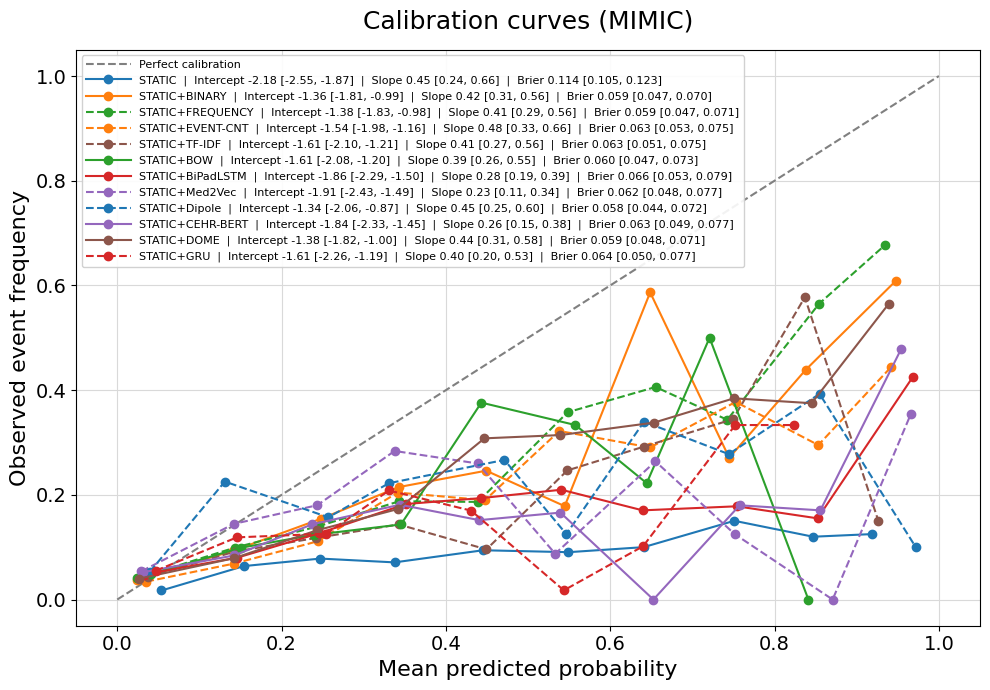

In [9]:
import matplotlib.pyplot as plt
import numpy as np


def plot_calibration_curves_(
    methods,
    summary,
    curves,
    dataset,
    method_styles,
    bands=None,
    show_ci_band=False,
    figsize=(20, 11),
    legend_fontsize=8,
    show=True,
):
    """Plot calibration curves with summary metrics and optional CI bands.

    Colors repeat every six methods, with a different line style each cycle.

    Args:
        methods: Iterable of method component sequences joined with "+".
        summary: Mapping from method names to metric DataFrames containing
            "mean", "ci95_low", and "ci95_high" columns.
        curves: Mapping from method names to (x, observed) pairs.
        dataset: Dataset name displayed in the title.
        bands: Optional mapping from method names to (x, low, high) CI arrays.
        show_ci_band: Whether to display confidence interval bands.
        figsize: Figure width and height in inches.
        legend_fontsize: Legend font size in points.
        show: Whether to display the figure.

    Returns:
        A tuple containing the figure and axes.
    """
    if show_ci_band and bands is None:
        raise ValueError("bands must be provided when show_ci_band=True.")

    method_names = ["+".join(method) for method in methods]

    def metric_label(stats, name, decimals):
        row = stats.loc[name]
        return (
            f"{name} {row['mean']:.{decimals}f} "
            f"[{row['ci95_low']:.{decimals}f}, "
            f"{row['ci95_high']:.{decimals}f}]"
        )

    # Create labels before plotting
    labels = {}
    for method in method_names:
        stats = summary[method]
        labels[method] = (
            f"{method}  |  "
            f"{metric_label(stats, 'Intercept', 2)}  |  "
            f"{metric_label(stats, 'Slope', 2)}  |  "
            f"{metric_label(stats, 'Brier', 3)}"
        )

    fig, ax = plt.subplots(figsize=figsize)

    ax.plot(
        [0, 1], [0, 1],
        "--",
        color="gray",
        label="Perfect calibration",
    )

    for method in method_names:
        x, observed = curves[method]
        style = method_styles[method]

        ax.plot(
            x,
            observed,
            marker="o",
            color=style["color"],
            linestyle=style["linestyle"],
            label=labels[method],
        )

        if show_ci_band:
            band_x, low, high = (
                np.asarray(values) for values in bands[method]
            )
            valid = (
                np.isfinite(band_x)
                & np.isfinite(low)
                & np.isfinite(high)
            )
            ax.fill_between(
                band_x[valid],
                low[valid],
                high[valid],
                color=style["color"],
                alpha=0.18,
            )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.tick_params(axis="both", labelsize=14)
    ax.set_xlabel("Mean predicted probability", fontsize=16)
    ax.set_ylabel("Observed event frequency", fontsize=16)
    ax.set_title(f"Calibration curves ({dataset})", fontsize=18, pad=15)
    ax.grid(True, color="0.85", linewidth=0.8)
    ax.set_axisbelow(True)

    ax.legend(
        loc="upper left",
        #bbox_to_anchor=(0.02, 0.90),
        handlelength=4,
        fontsize=legend_fontsize,
        frameon=True,
        framealpha=0.9,
    )

    fig.tight_layout()

    if show:
        plt.show()

    return fig, ax


fig, ax = plot_calibration_curves_(
    methods=args.methods,
    summary=summary,
    curves=curves,
    dataset=dataset,
    method_styles=method_styles,
    bands=bands,
    figsize=(10, 7),
    legend_fontsize=8,
    show_ci_band=False,
)